In [1]:
import glob
import matplotlib.pyplot as plt
#import urllib.request
import xarray as xr
import matplotlib as mpl
import calendar
import datetime as dt
import cartopy as cart
import numpy as np
import pandas as pd
import scipy.stats as stats
import xeofs as xe
from scipy.stats import pearsonr
from scipy.special import gammainc
# Do a Fourier/Wavelet analysis.
from scipy.fftpack import fft
from statsmodels.tsa.seasonal import seasonal_decompose
import pywt
from eofs.standard import Eof
import scipy.signal 



### HadISST Satelite/in-situ Dataset (1870-present)

I - Introduction -- Navigating a NetCDF file:

1. Loading the HadISST.nc file dataset as an xarray object.
2. Plotting sea surface temperature (SST).
3. Introduce climatologies with a baseline of 1991-2020.
4. Introduce anomalies with respect to the climatology.

### I-1. Loading the nc file

In climate science, collected data across various dimensions are typically stored as an .nc file or NetCDF (Network Common Data Form) file [1]. These files contain and separate the dimensional data and variables:

    i) Dimensional data: Represents a coordinate, such as time, longitude, latitude, and depth/height. Each coordinate has a name, length, and descriptive attributes, such as a longer form name.

    ii) Variable data: Arrays of the same type that have a name, array shape, data-type, and descriptive attributes. If a variable contains the same name as a dimension, then it is a coordinate variable.

Working with a NetCDF dataset can be quite gruelsome and daunting. Fortunately, geoscience, being a well-established field of study, brings with it a high-level, intuitive python object called an `xarray`[2] that is designed to manipulate and work well with NetCDF files. Separating coordinate and data variables as their own objects, it is simple to navigate the dataset as a whole and change the dataset based on coordinate restrictions, such as looking at a select area, applying a mask, or performing statistics.

To get started, we can load the NetCDF file:

---
[1] AgriMetSoft, 2020. https://agrimetsoft.com/faq/What%20is%20an%20NC%20file%20(NetCDF)

[2] xarray Developers, 2014-2024. https://docs.xarray.dev/en/stable/
 

In [2]:
# Load the HadISST dataset.
dsHadISST = xr.open_dataset('HadISST_sst.nc')

In [4]:
# What an xarray dataset looks like.
dsHadISST

<xarray.Dataset>
Dimensions:    (time: 1840, nv: 2, latitude: 180, longitude: 360)
Coordinates:
  * time       (time) datetime64[ns] 1870-01-16T11:59:59.505615234 ... 2023-0...
  * latitude   (latitude) float32 89.5 88.5 87.5 86.5 ... -87.5 -88.5 -89.5
  * longitude  (longitude) float32 -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
Dimensions without coordinates: nv
Data variables:
    time_bnds  (time, nv) float32 ...
    sst        (time, latitude, longitude) float32 ...
Attributes:
    Title:                      Monthly version of HadISST sea surface temper...
    description:                HadISST 1.1 monthly average sea surface tempe...
    institution:                Met Office Hadley Centre
    source:                     HadISST
    reference:                  Rayner, N. A., Parker, D. E., Horton, E. B., ...
    Conventions:                CF-1.0
    history:                    5/6/2023 converted to netcdf from pp format
    supplementary_information:  Updates and supplementary information will be...
    comment:                    Data restrictions: for academic research use ...

### I-2. Plotting Sea Surface Temperature 
With the NetCDF file loaded, it would be nice to see what exactly we are working with to get a sense of the data. Here, our data variable is the sea surface temperature (SST) collected through in-situ boat expeditions as early as 1870 to the present, meshed with satellite data. SST is the temperature of the sea from surface level to a depth of $1200$ m, with time, longitude, and latitude as its associated coordinate dimensions.

This dataset in particular contains a value of $-1000$ where there is no data. Having such a low value can ruin the contour plot. A simple solution is to simply change all $-1000$ values to NaNs and ignore the NaNs in our calculations, which `xarray` can do so already.

In [3]:
# Make the time dimension divisible by 12, i.e., all years < 2023.
dsHadISST = dsHadISST.isel(time = dsHadISST.time.dt.year < 2023)

# Change all -1000 values (i.e., no data) to NaN for contour plotting reasons.
dsHadISST = dsHadISST.where(dsHadISST.sst != -1000)

# Add 180 to change coordinates from (-180 to 180) to (0 to 360).
dsHadISST = dsHadISST.assign_coords(longitude=(dsHadISST.longitude + 180))

# Roll the data so that the 0 degree longitude is in the middle.
dsHadISST = dsHadISST.roll(longitude=180)

For a sense of reference, we put a land and coastline map. 

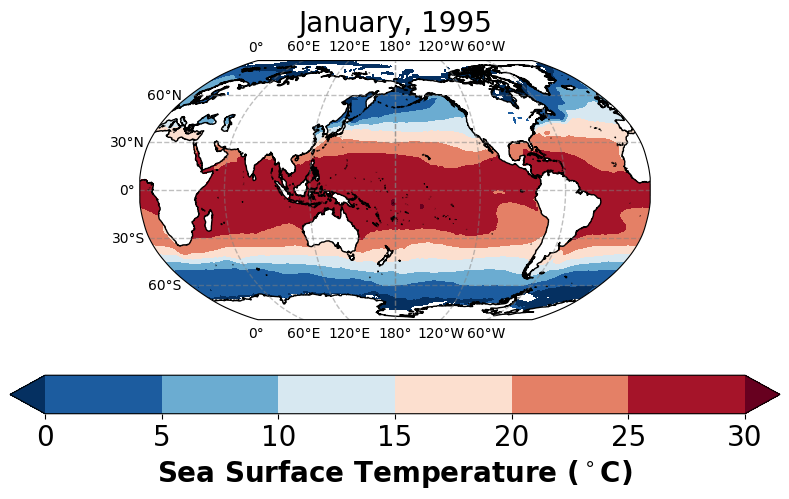

In [4]:
# Some plotting functions
def draw_map(figsize,l_0):
    """
    Draw a map with coastlines and land.

    Parameters
    ----------
            figsize : tuple
                      Figure size in inches.

                l_0 : float
                      Central longitude.

    Returns
    -------
            fig : matplotlib.figure.Figure
                  Figure object.

             ax : matplotlib.axes._subplots.AxesSubplot
                  Axes object.
    """
    
    proj = {'projection' : cart.crs.Robinson(central_longitude=l_0)}
    
    fig, ax = plt.subplots(figsize=figsize, subplot_kw=proj)
    gl = ax.gridlines(draw_labels=True, linewidth=1, color='grey', alpha=0.5, linestyle='--')
    return fig,ax

def date_time(date_times):
    """
    Get the year and month from a datetime object.
    """
    date_times = dt.datetime.strptime(str(date_times), '%Y-%m-%dT%H:%M:%S.%f000')
    year = date_times.year
    month = calendar.month_name[date_times.month]
    return month,year
    
    
# Data for plotting
x = dsHadISST.longitude
y = dsHadISST.latitude
z = dsHadISST.sst[1500,:,:] # Pick a datetime.

# Date time.
month,year = date_time(dsHadISST.time[1500].values)

# Plotting parameters.
l_0 = 180
res = "50m"
figsize = (8,5)

# Plotting the map with sea surface temperature contours.
fig, ax = draw_map(figsize,l_0)

m = ax.contourf(x, y, z, 
                    cmap='RdBu_r', extend='both', transform = cart.crs.PlateCarree())

ax.coastlines(resolution=res, color='black')
ax.tick_params(size=20)
ax.set_title(month+', '+str(year), fontsize=20)
cbar = plt.colorbar(m, ax=ax, label='Sea Surface Temperature ($^\circ$C)',orientation='horizontal') 
cbar.ax.tick_params(labelsize=20)   
cbar.ax.set_xlabel('Sea Surface Temperature ($^\circ$C)', fontsize=20, fontweight='bold')

plt.tight_layout()


Here, we can see a predictable trend: near the equator, at the tropics, a latitude of $30^{\circ}$ S to $30^{\circ}$ N, we have a bulk of warm water, while at the northern and southern parts of the ocean, we have cold water. This makes sense at an intuitive level, as the sun's rays are more direct at the equator and less so at the poles. So, the data makes sense, which is a good start, but we want to see how climate is changing.  

### I-3. Calculating Climatology
Climate is relatively stationary at an annual timescale. To observe and calculate any differences, an average over a long period of time must be used. We call this type of long-term averaging of a climate data variable a climatology[3]. Here, we'll be using a 30 year baseline from 1991-2020. 

To restrict our xarray dataset, we use the `isel` function with the constraints that the time coordinate must be between and including the years 1991 and 2020. This 'selects' the data that contains only those years and applies it to all data variables and time data variable.

Please note, the `.dt` method stands for datetime and organizes datetime data-types, which the time coordinate data variable is.

----
[3] https://iridl.ldeo.columbia.edu/dochelp/StatTutorial/Climatologies/index.html


In [5]:
dsHadISST_Baseline = dsHadISST.isel(
    time=(dsHadISST.time.dt.year >= 1991) & (dsHadISST.time.dt.year <= 2020))

In [6]:
# Calculate 1991-2020 climatology.
gb = dsHadISST_Baseline.groupby('time.month') # Collect each month.
clim = gb.mean(dim='time') # 30 year (1991 to 2020) long-term average of each month.


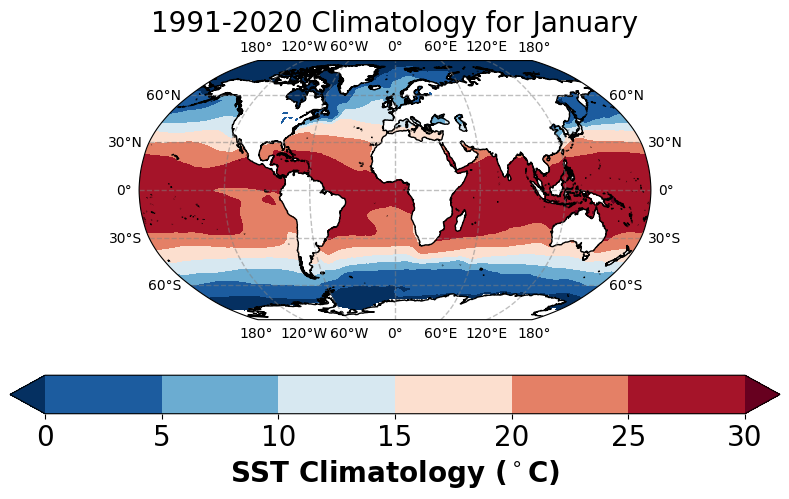

In [9]:
# Data for plotting
x = clim.longitude
y = clim.latitude
z = clim.sst[0,:,:]

# Date time.
month = calendar.month_name[1]

# Plotting parameters.
l_0 = 0
res = "50m"
figsize = (8,5)

# Plotting the map with sea surface temperature contours.
fig, ax = draw_map(figsize,l_0)

m = ax.contourf(x, y, z, 
                    cmap='RdBu_r', extend='both', transform = cart.crs.PlateCarree())
ax.coastlines(resolution=res, color='black')
ax.tick_params(size=20)
ax.set_title('1991-2020 Climatology for '+month, fontsize=20)
cbar = plt.colorbar(m, ax=ax, label='Sea Surface Temperature ($^\circ$C)',orientation='horizontal') 
cbar.ax.tick_params(labelsize=20)   
cbar.ax.set_xlabel('SST Climatology ($^\circ$C)', fontsize=20, fontweight='bold')

plt.tight_layout()


Once again, we can see the same trend with warm water at the tropics and cold water nearer to the south and north. But we want to observe change.

### I-4. Calculating Sea Surface Temperature Anomalies

If climate is relatively stable over a long period of time, then the long-term average is a great metric to see if any change will occur. To see the difference, we subtract the long-term average from the SST. If any difference is observed, we call this an anomaly. In this case, it is called a sea surface temperature anomaly (SSTA).

In [7]:
# Calculate sea surface temperature anomalies with respect to 1991-2020 baseline.
gb = dsHadISST.groupby('time.month')
anom = gb - clim

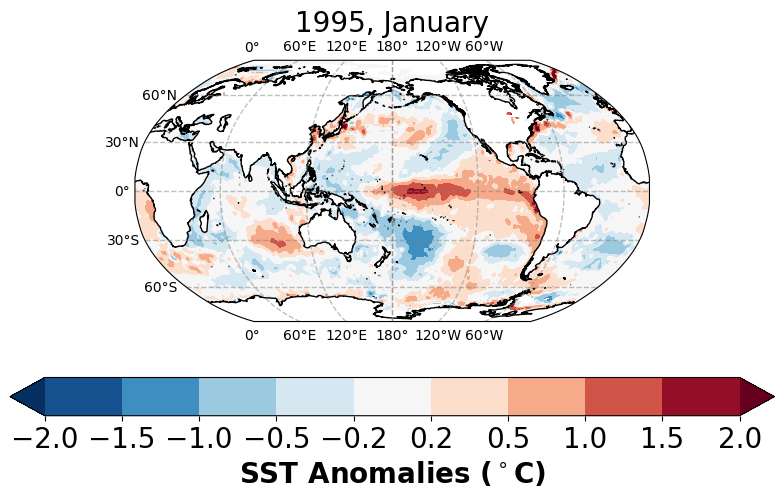

In [14]:
# Data for plotting
k = 1500
x = anom.longitude
y = anom.latitude
z = anom.sst[1500,:,:]

# Date time.
month,year = date_time(anom.time[1500].values)

# Plotting parameters.
l_0 = 180
res = "50m"
figsize = (8,5)

# Plotting the map with sea surface temperature contours.
fig, ax = draw_map(figsize,l_0)

# Specify contour levels
contour_levels = [-2, -1.5, -1, -0.5, -0.2, 0.2, 0.5, 1.0, 1.5, 2]
m = ax.contourf(x, y, z, 
                    cmap='RdBu_r',levels=contour_levels,extend='both', transform = cart.crs.PlateCarree())
ax.coastlines(resolution=res, color='black')
ax.tick_params(size=20)
ax.set_title(str(year)+', '+month, fontsize=20)
cbar = plt.colorbar(m, ax=ax, label='Sea Surface Temperature ($^\circ$C)',orientation='horizontal') 
cbar.ax.tick_params(labelsize=20)   
cbar.ax.set_xlabel('SST Anomalies ($^\circ$C)', fontsize=20, fontweight='bold')
#cbar.ax.set_xticklabels(['< -2','-2','-1.5','-1','-0.5','-0.2','0.2','0.5','1','1.5','2','> 2'])

plt.tight_layout()
plt.savefig('SST-Anomalies.svg',dpi=300)

Here, we see for the month of January during the year 1995, there's quite a bit of anomalious action going on. One anomaly that is of note is the particularly large region of anomalously warm water near a latitude of $-5^{\circ}$ S to $5^{\circ}$ N and longitude of $100^{\circ}$ W going westward to $160^{\circ}$ E. This region is known as the nino index. When this the nino index has a SSTA $> 0.5$, we are in naturally warmer state called an El Nino, when SSTA $< 0.5$, we are in a naturally colder stated called a La Nina (expand). 

### II-Natural Phenomena -- The El Nino-Southern Oscillation (ENSO)

1. Manipulating longitudinal coordinates for wrap-around issues.
2. Averaging over the latitude to see the temporal-longitudinal dynamics.
3. Obtaining a time-series of ENSO.

Now, not all anomalious are an immediate sign of distress, some anomalies are quite natural and follow a stable cycle, although human activity can exacerbate some of these more natural cycles. To get a better sense of what one of these natural cycles looks like, we can zoom in on the Nino index [4].

----
[4] UCAR, 2023. https://climatedataguide.ucar.edu/climate-data/nino-sst-indices-nino-12-3-34-4-oni-and-tni


Now, we select the Nino region with $-5 \leq$ latitude $\leq 5$ and $140 \leq$ longitude $\leq 260$.

In [11]:
Nino = anom.sel(latitude = (anom.latitude >= -5) & (anom.latitude <= 5),
                       longitude = (anom.longitude >= 140) & (anom.longitude <= 260)) # select Nino region

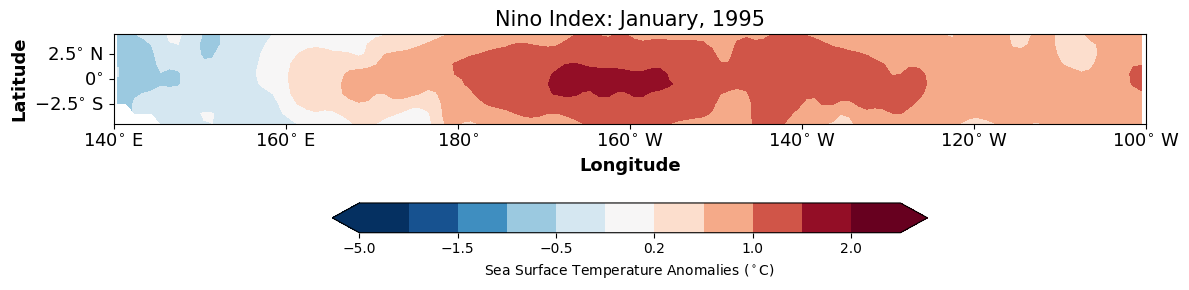

In [12]:
# Data for plotting
x = Nino.longitude
y = Nino.latitude
z = Nino.sst[1500,:,:] # Pick a datetime.

# Date time.
month,year = date_time(Nino.time[1500].values)

# Plotting parameters.
vmin = -2
vmax = 2
l_0 = 0
figsize = (12,3)

# Plotting the map with sea surface temperature contours.
#fig, ax = draw_map(figsize,l_0)
fig, ax = plt.subplots(figsize=figsize)

# Specify contour levels
contour_levels = [-5,-2, -1.5, -1, -0.5, -0.2, 0.2, 0.5, 1.0, 1.5, 2,5]

contour = ax.contourf(x,y,z,cmap='RdBu_r',levels=contour_levels,extend='both', vmin=-2, vmax=2)

cbar = plt.colorbar(contour, ax=ax,orientation='horizontal',pad=0.4)
cbar.set_label('Sea Surface Temperature Anomalies ($^\circ$C)')
ax.set_xticks([140,160,180,200,220,240,260])#, crs=cart.crs.PlateCarree(central_longitude=180))
ax.set_xticklabels(["$140^{\circ}$ E", "$160^{\circ}$ E", "$180^{\circ}$", "$160^{\circ}$ W", "$140^{\circ}$ W", "$120^{\circ}$ W", "$100^{\circ}$ W"])
ax.set_yticks([-2.5,0,2.5])#, crs=cart.crs.PlateCarree(central_longitude=180))
ax.set_yticklabels(["$-2.5^{\circ}$ S", "$0^{\circ}$", "$2.5^{\circ}$ N"])
ax.tick_params(labelsize=13)
ax.set_ylabel('Latitude', fontsize=13, fontweight='bold')
ax.set_xlabel('Longitude', fontsize=13, fontweight='bold')
ax.set_title('Nino Index: '+month+', '+str(year), fontsize=15)
plt.tight_layout()


### II-2. Latitude-Average

What we really care about is a cycle in time. We can take the average over the latitude to see this directly:

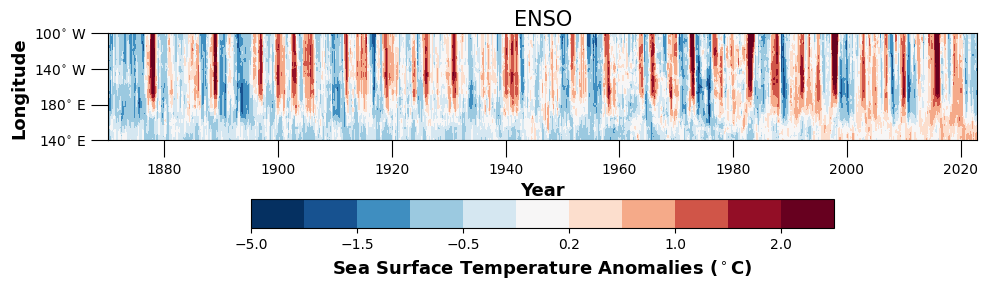

In [13]:
ENSO = Nino.mean(dim=['latitude'])

# Data for plotting
x = ENSO.time
y = ENSO.longitude
z = ENSO.sst.T # Pick a datetime.

# Plotting parameters.
vmin = -2
vmax = 2
l_0 = 0
figsize = (10,3)

# Plotting the map with sea surface temperature contours.
fig, ax = plt.subplots(figsize=figsize)

# Specify contour levels
contour_levels = [-5,-2, -1.5, -1, -0.5, -0.2, 0.2, 0.5, 1.0, 1.5, 2,5]

contour = ax.contourf(x,y,z,cmap='RdBu_r',levels=contour_levels, vmin=-2, vmax=2)

cbar = plt.colorbar(contour, ax=ax,orientation='horizontal',pad=0.3)
cbar.set_label('Sea Surface Temperature Anomalies ($^\circ$C)', fontsize=13, fontweight='bold')
ax.set_yticks([140,180,220,260])
ax.set_yticklabels(["$140^{\circ}$ E", "$180^{\circ}$ E", "$140^{\circ}$ W", "$100^{\circ}$ W"])
ax.tick_params(size=12)
ax.set_xlabel('Year', fontsize=13, fontweight='bold')
ax.set_ylabel('Longitude', fontsize=13, fontweight='bold')
ax.set_title('ENSO', fontsize=15)
plt.tight_layout()
plt.savefig('ENSO_Lon.svg',dpi=300)



What emerges is indeed a cycle, flowing from an abnormally hot period to an abnormally cold period. We can also see that in the more east side of the nino index, there is no cycle (it also begins to become more warm as the 2020's are approached). To get a better view of this cycle, let's zoom in from 1980 to 2023:

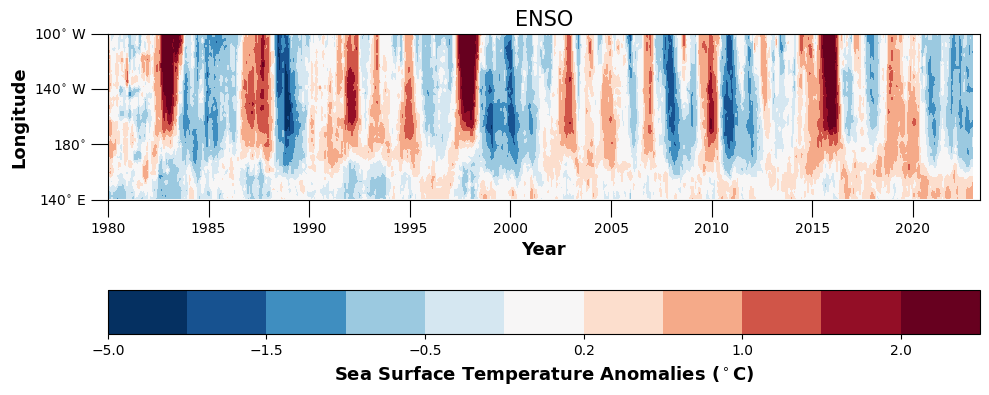

In [18]:
# Data for plotting
x = ENSO.time
y = ENSO.longitude
z = ENSO.sst.T

# Plotting parameters.
vmin = -2
vmax = 2
l_0 = 0
figsize = (10,4)

# Plotting the map with sea surface temperature contours.
fig, ax = plt.subplots(figsize=figsize)

# Specify contour levels
contour_levels = [-5,-2, -1.5, -1, -0.5, -0.2, 0.2, 0.5, 1.0, 1.5, 2,5]

contour = ax.contourf(x,y,z,cmap='RdBu_r',levels=contour_levels, vmin=-2, vmax=2)

cbar = plt.colorbar(contour, ax=ax,orientation='horizontal',pad=0.3)
cbar.set_label('Sea Surface Temperature Anomalies ($^\circ$C)', fontsize=13, fontweight='bold')
ax.set_yticks([140,180,220,260])#, crs=cart.crs.PlateCarree(central_longitude=180))
ax.set_yticklabels(["$140^{\circ}$ E", "$180^{\circ}$", "$140^{\circ}$ W", "$100^{\circ}$ W"])
ax.tick_params(size=12)
ax.set_xlabel('Year', fontsize=13, fontweight='bold')
ax.set_ylabel('Longitude', fontsize=13, fontweight='bold')
ax.set_title('ENSO', fontsize=15)
ax.set_xlim([dt.datetime(1980,1,1),dt.datetime(2023,5,1)])
plt.tight_layout()


The El Nino-Southern Oscillation seems to be quite irregular: Containing both strong and weaker warm periods, strong and weaker cold periods, and long and short bursts.

### II-3. ENSO time-series 

Obtaining a time-series of this cycle would be beneficial. Note that the east Nino region does not contain a strong cycle. We can safely remove it from our analysis and focus on the so-called Nino 3.4 index [5]:

----
[5] renberth, Kevin & National Center for Atmospheric Research Staff (Eds). Last modified 2023-07-25 "The Climate Data Guide: Nino SST Indices (Nino 1+2, 3, 3.4, 4; ONI and TNI).” Retrieved from https://climatedataguide.ucar.edu/climate-data/nino-sst-indices-nino-12-3-34-4-oni-and-tni on 2023-11-10.



In [19]:
# Remove the eastern longitudinal coordinates.
ENSO = ENSO.sel(longitude = (ENSO.longitude >= 190))

Now, to obtain a time-series, let us take the average of the longitude across the Nino 3.4 index:

In [20]:
ENSO_ts = ENSO.mean(dim=['longitude'])

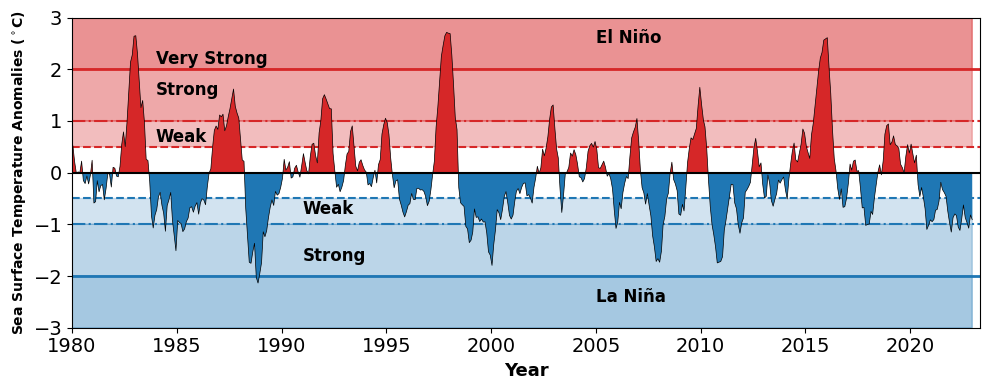

In [21]:
# Data for plotting
x = ENSO_ts.time
y = ENSO_ts.sst

# Date time.
#month,year = datetime(Nino.time[1500].values)

# Plotting parameters.
figsize = (10,4)

# Plotting the map with sea surface temperature contours.
fig = plt.figure(figsize=figsize)

plt.axhline(0,color='k')
plt.axhline(0.5,linestyle='--',color='tab:red')
plt.axhline(1,linestyle='-.',color='tab:red')
plt.axhline(2,color='tab:red',linewidth=2)
plt.axhline(-0.5,linestyle='--',color='tab:blue')
plt.axhline(-1,linestyle='-.',color='tab:blue')
plt.axhline(-2,color='tab:blue',linewidth=2)
plt.fill_between(x,0.5,1,color='tab:red',alpha=0.3)
plt.fill_between(x,1,2,color='tab:red',alpha=0.4)
plt.fill_between(x,2,3,color='tab:red',alpha=0.5)
plt.fill_between(x,-0.5,-1,color='tab:blue',alpha=0.2)
plt.fill_between(x,-1,-2,color='tab:blue',alpha=0.3)  
plt.fill_between(x,-2,-3,color='tab:blue',alpha=0.4)
plt.plot(x,y,color='k',linewidth=0.5)
plt.xlabel('Year',size=13,fontweight='bold')
plt.ylabel('Sea Surface Temperature Anomalies ($^\circ$C)',size=10,fontweight='bold')
plt.tick_params(labelsize=14)
plt.fill_between(x, y, 0, where=y >= 0, facecolor='tab:red', interpolate=True)
plt.fill_between(x, y, 0, where=y <= 0, facecolor='tab:blue', interpolate=True)
plt.ylim([-3,3])
plt.xlim([dt.datetime(1980,1,1),dt.datetime(2023,5,1)])

plt.text(dt.datetime(1984,1,1),0.6,'Weak',fontsize=12,fontweight='bold')
plt.text(dt.datetime(1984,1,1),1.5,'Strong',fontsize=12,fontweight='bold')
plt.text(dt.datetime(1984,1,1),2.1,'Very Strong',fontsize=12,fontweight='bold')
plt.text(dt.datetime(1991,1,1),-0.8,'Weak',fontsize=12,fontweight='bold')
plt.text(dt.datetime(1991,1,1),-1.7,'Strong',fontsize=12,fontweight='bold')
plt.text(dt.datetime(2005,1,1),-2.5,'La Niña',fontsize=12,fontweight='bold')
plt.text(dt.datetime(2005,1,1),2.5,'El Niño',fontsize=12,fontweight='bold')
plt.tight_layout()
plt.savefig('ENSO.svg',dpi=300)



Plot was reproduced from [5].

Here, we can see a very clear cycle, but what is the frequency of such a dynamic cycle?

### III-Observing Major Events through Maximizing Covariance

1. SSTA detrending trends and cycles
3. Applying Empirical Orthogonal Function (EOF) analysis on the detrended SSTA data.


### III-1. Trends and Cycles.

Some patterns are quite noticeable even at the global scale across a relatively short period of time, such as the ENSO. Yet, it might be helpful to detect such an anomaly across the globe without looking into the data itself. First, to minimize bias, let us detrend the data. As an example, we will be detrending the global SSTA by treating the time-series as a sum of a trend, seasonal cycle(s*), and noise (this also has the further application of creating a forecast, but we won't be dealing with that here).

\* A time-series can be composed of multiple seasonal cycles.

### 

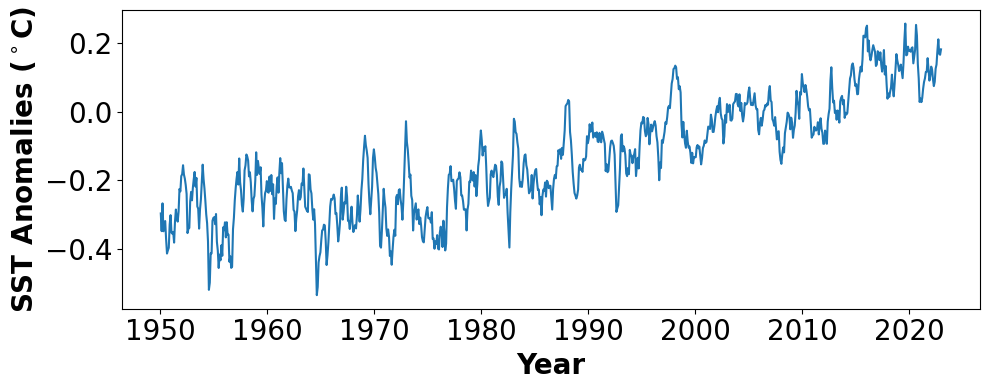

In [22]:
# Data for plotting
start_year = 1950
end_year = 2023
temp = anom.isel(time=(anom.time.dt.year >= 1950) & (anom.time.dt.year <= 2023))

global_anom = temp.mean(dim=['longitude','latitude'])
global_std = temp.std(dim=['longitude','latitude'])

x = global_anom.time
y = global_anom.sst

# Date time.
#month,year = datetime(Nino.time[1500].values)

# Plotting parameters.
figsize = (10,4)
fig = plt.figure(figsize=figsize)

plt.plot(x,y)
plt.xlabel('Year',size=20,fontweight='bold')
plt.ylabel('SST Anomalies ($^\circ$C)',size=20,fontweight='bold')
plt.tick_params(labelsize=20)

plt.tight_layout()


There's a clear upwards trend, we wish to detrend this. To do so, we'll be treating it as a linear trend and simply subtract this value from the original series:

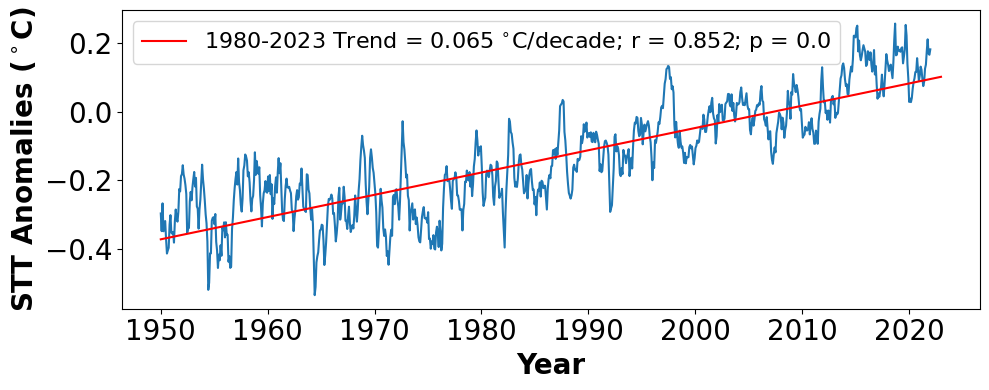

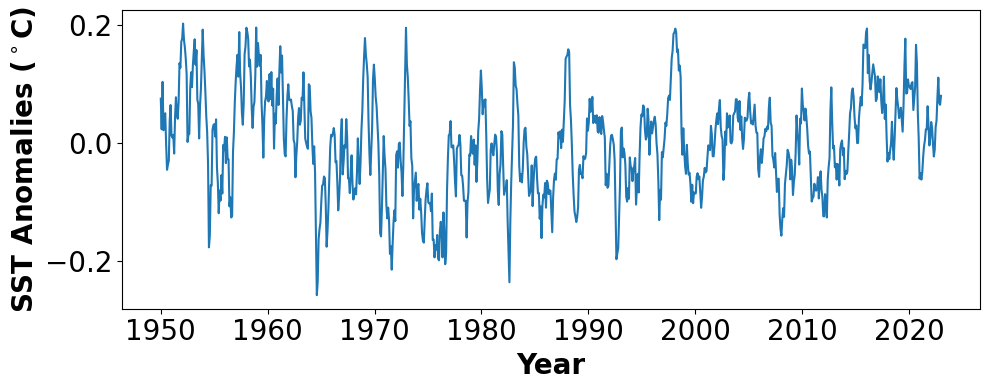

In [23]:

# Linear trend finding
y = global_anom.sst
x = np.linspace(1950,2023,len(y))
slope, intercept, r_value, p_value, std_err = stats.linregress(x,y) # Linear regression

# Linear trend line
line = slope*x+intercept
# Plotting parameters.
figsize = (10,4)
fig = plt.figure(figsize=figsize)

plt.plot(np.linspace(global_anom.time.dt.year[0],global_anom.time.dt.year[-1],len(global_anom.time)),global_anom.sst)
plt.plot(x,line,'r',label='1980-2023 Trend = '+str(round(slope*10,3))+' $^{\circ}$C/decade;' + ' r = '+str(round(r_value,3))+'; p = '+str(round(p_value,3)))
plt.xlabel('Year',size=20,fontweight='bold')        
plt.ylabel('STT Anomalies ($^\circ$C)',size=20,fontweight='bold')
plt.tick_params(labelsize=20)
plt.legend(fontsize=16)
plt.tight_layout()  
plt.savefig('Global_SST_Trend.svg',dpi=300)

fig = plt.figure(figsize=figsize)
y -= line
plt.plot(x,y)
plt.xlabel('Year',size=20,fontweight='bold')        
plt.ylabel('SST Anomalies ($^\circ  $C)',size=20,fontweight='bold')
plt.tick_params(labelsize=20)
plt.tight_layout()
plt.savefig('Global_SST_Trend_Removed.svg',dpi=300)




Great. Using this detrended time-series, the seasonal cycle can be calculated and subsequently eliminated:

Now, we perform this detrending to each pixel on the SSTA data:

In [24]:
linex = xr.DataArray(line, dims=('time'), coords={'time': global_anom.time})
g = temp - linex
yearly_means = g.groupby('time.year').mean(dim='time')
Global = g.groupby('time.year') - yearly_means

### III-2: Empirical Orthogonal Function (EOF) Analysis.

With the dataset completely detrended, we can perform some EOF analysis on it to see the regions involved in the most variance as well as its associated principal component time-series. The eigenvalues ordered from highest to lowest, describe the leading modes who showcase how much of the variance can be explained. If the eigenvalues overlap by error, then the eof modes can be taken to be the same by adding them together, their principal component modes are combined together as well.

No overlap between eigenvalues.


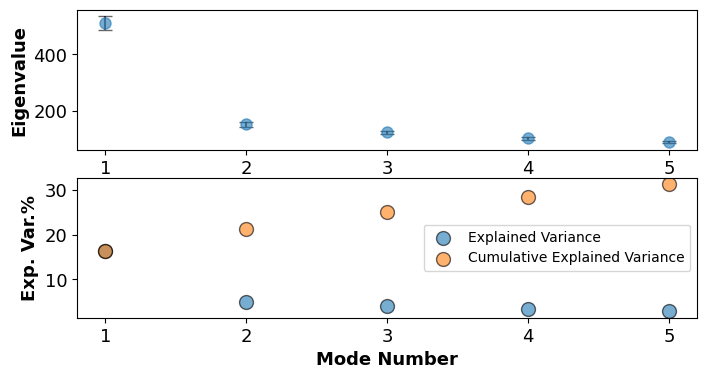

In [25]:
def get_EOF(dataset,n):
    """
    Calculate the first n EOFs of the dataset.

    Parameters
    ----------
        dataset : xarray.core.dataset.Dataset
                    An xarray dataset.
    
                n : int
                    The number of EOFs to calculate.

    Returns
    -------
        eof : numpy.ndarray
                The EOFs.

            pc : numpy.ndarray
                The PCs.

        varfrac : numpy.ndarray
                The variance fraction.

        lambdas : numpy.ndarray
                The eigenvalues.
    """
    
    lat = dataset.latitude.values
    lon = dataset.longitude.values
    data = dataset.sst.values
    T = len(dataset.time.values) # Number of time steps.

    # Define weights
    weights   = np.cos(np.deg2rad(lat))
    weights   = weights.reshape(len(weights), 1)

    # Perform EOF (Spatial) & Principal Component (Temporal) analysis.
    solver = Eof(data, weights=weights)
    eof = solver.eofs(neofs=n)
    pc  = solver.pcs(npcs=n, pcscaling=0)
    varfrac = solver.varianceFraction()
    lambdas = solver.eigenvalues()

    # Plot the first n eigenvalues & their error (North et al., 1982).
    Delta_lambda = lambdas*np.sqrt(2/T)

    flag = 0
    for i in range(1,n):
        if (lambdas[i-1] - Delta_lambda[i-1]) < (lambdas[i] + Delta_lambda[i]): 
            print('Overlap between eigenvalues '+str(i)+' and '+str(i+1)+'.')
            flag = 1
    
    if flag == 0:
        print('No overlap between eigenvalues.')

    fig,ax = plt.subplots(nrows=2,ncols=1,figsize=(8,4))
    ax[0].errorbar(np.arange(1,n+1),lambdas[0:n],Delta_lambda[0:n],fmt='o',capsize=5,markersize=8,ecolor='k',alpha=0.6)
    ax[0].set_xlabel('Mode Number',size=13,fontweight='bold')
    ax[0].set_ylabel('Eigenvalue',size=13,fontweight='bold')
    ax[0].set_xticks(np.arange(1,n+1))
    ax[0].tick_params(labelsize=13)   

    # Plot Explained Variance.
    ax[1].scatter(np.arange(1,n+1),varfrac[0:n]*100,s=100,edgecolors='k',alpha=0.6,label=r'Explained Variance')
    ax[1].scatter(np.arange(1,n+1),np.cumsum(varfrac[0:n]*100),s=100,edgecolors='k',alpha=0.6,label=r'Cumulative Explained Variance')
    ax[1].set_xlabel('Mode Number',size=13,fontweight='bold')
    ax[1].set_ylabel('Exp. Var.%',size=13,fontweight='bold')
    ax[1].set_xticks(np.arange(1,n+1))
    ax[1].tick_params(labelsize=13)
    ax[1].legend(fontsize=10)

    return eof,pc,varfrac,lambdas

Global_eof,Global_pc,Global_varfrac,Global_lambdas = get_EOF(Global,5)


There was no overlap between the eigenvalues, so each mode can be independently represented.

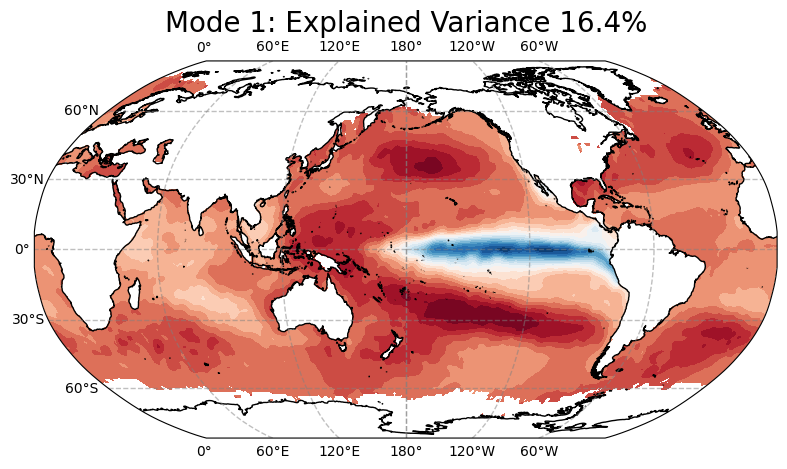

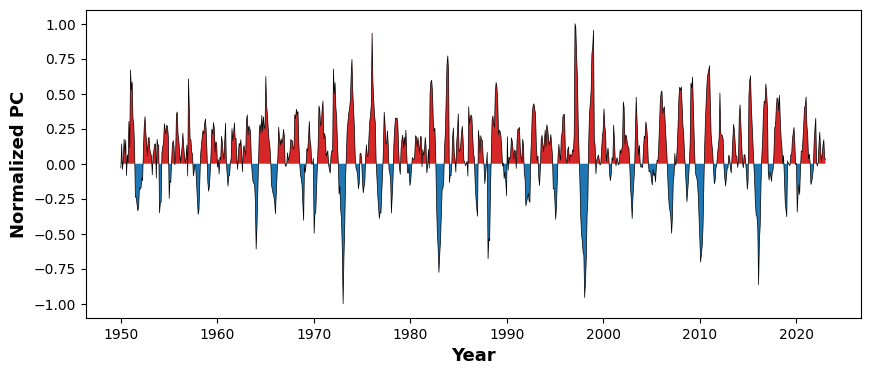

In [26]:

def plot_EoF(eof,varfrac,lon,lat,k,sign=1,l_0=180):

    # Data for plotting
    x = lon
    y = lat
    z = sign*eof[k,:,:]
    z_temp = sign*eof[k,~np.isnan(eof[k,:,:])]

    # Plotting parameters.
    vmin = np.min(z_temp)
    vmax = np.max(z_temp)
    res = "50m"
    figsize = (8,5)

    # Plotting the map with sea surface temperature contours.
    fig, ax = draw_map(figsize,l_0)

    # Specify contour levels
    contour_levels = np.linspace(vmin,vmax,21)
    im = ax.contourf(x, y, z, 
                        cmap='RdBu_r',levels=contour_levels,vmin=vmin,vmax=vmax, transform = cart.crs.PlateCarree())
    ax.coastlines(resolution=res, color='black')
    for c in im.collections:
        c.set_rasterized(True)
    ax.set_title("Mode "+str(k+1)+": Explained Variance "+str(round(varfrac[k]*100,1))+"%", fontsize=20)
    plt.tight_layout()
    plt.savefig('EOF.svg',dpi=300)

def ts_norm(ts):
    A = max(ts) - np.abs(min(ts))
    ts = ts - A/2
    ts = ts/np.max([np.max(ts),np.abs(np.min(ts))])
    return ts

def plot_PC(x,pc):
    y = ts_norm(pc)
    fig = plt.figure(figsize=(10,4))
    plt.plot(x,y,linewidth=0.5,color='k')
    # Fill in greater than 0 red less than 0 blue
    plt.fill_between(x, y, 0, where=y >= 0, facecolor='tab:red', interpolate=True)
    plt.fill_between(x, y, 0, where=y <= 0, facecolor='tab:blue', interpolate=True)
    plt.xlabel('Year',size=13,fontweight='bold')
    plt.ylabel('Normalized PC',size=13,fontweight='bold')
    plt.savefig('PC.svg',dpi=300)


lat = Global.latitude.values
lon = Global.longitude.values
k = 0
sign = 1
l_0 = 180

plot_EoF(Global_eof,Global_varfrac,lon,lat,k,sign=sign,l_0=l_0)

x = np.linspace(start_year,end_year,len(Global.time))
plot_PC(x,Global_pc[:,k])


The first mode explains 16.4% of the total variance and the hot region in red is located in a region known as the El Nino index. This would suggest that the El Nino-Southern Oscillation (ENSO) is responsible for this mode. We will check this.

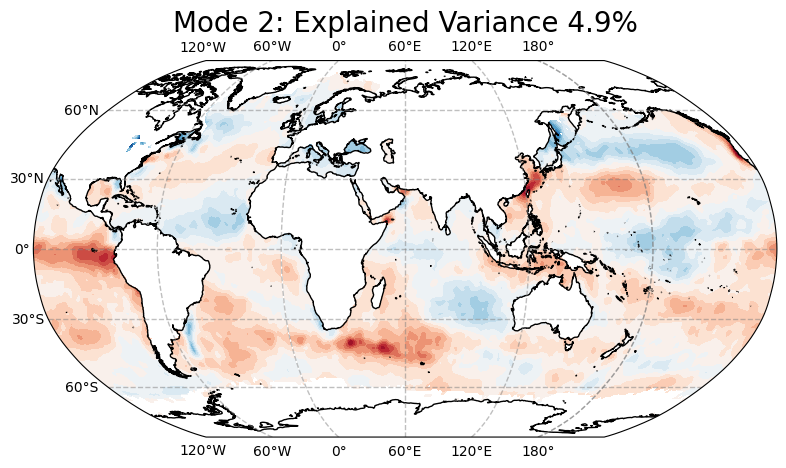

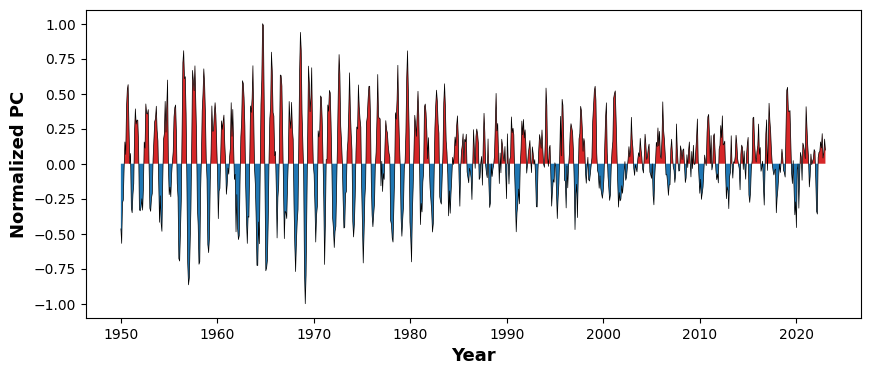

In [27]:
k = 1
sign = 1
l_0 = 60

plot_EoF(Global_eof,Global_varfrac,lon,lat,k,sign=sign,l_0=l_0)

x = np.linspace(start_year,end_year,len(Global.time))
plot_PC(x,Global_pc[:,k])

For the second mode, explaining 4.9% of the total variance, there is not a clear spatial pattern that could be matched to one of the mentioned ocean cycles.

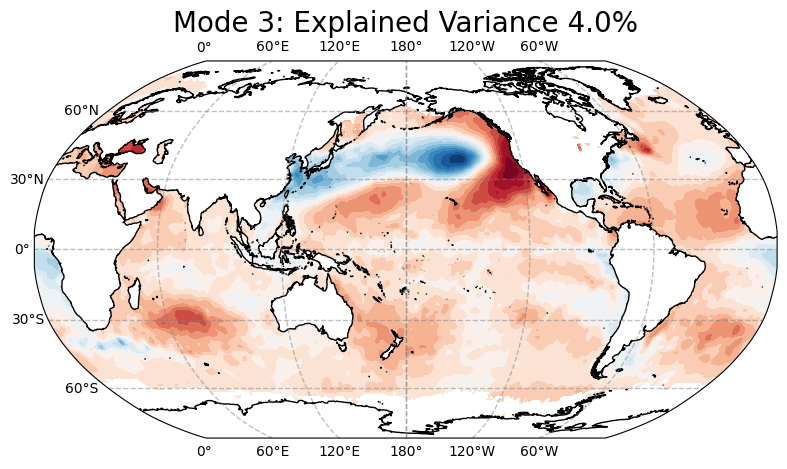

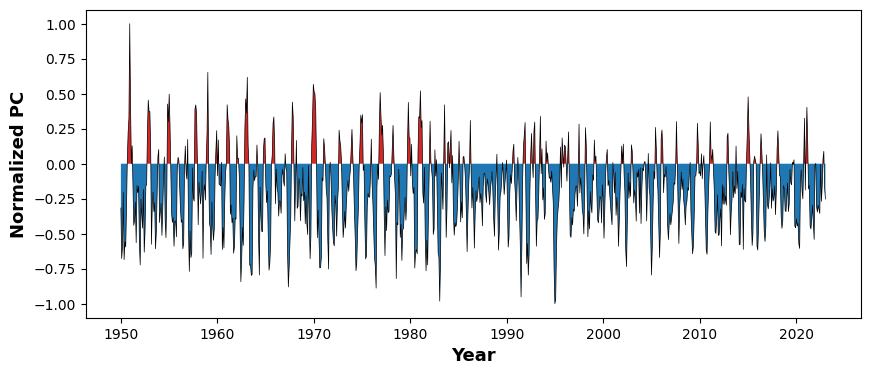

In [28]:
k = 2
sign = 1
l_0 = 180

plot_EoF(Global_eof,Global_varfrac,lon,lat,k,sign=sign,l_0=l_0)

x = np.linspace(start_year,end_year,len(Global.time))
plot_PC(x,Global_pc[:,k])

Mode 3 explains 4.0% of the total variance and is concentrated in the Northern and Central Pacific ocean, resembling the PDO and the El Nino Modoki, an anomalous cooling(warming) that is opposite to the ENSO.

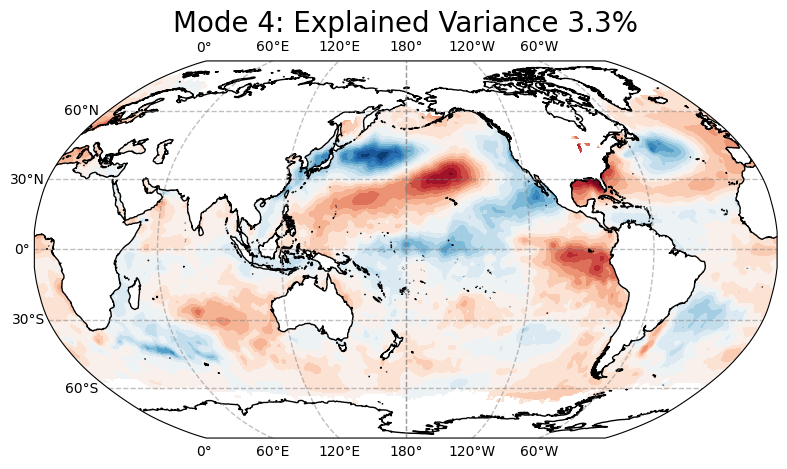

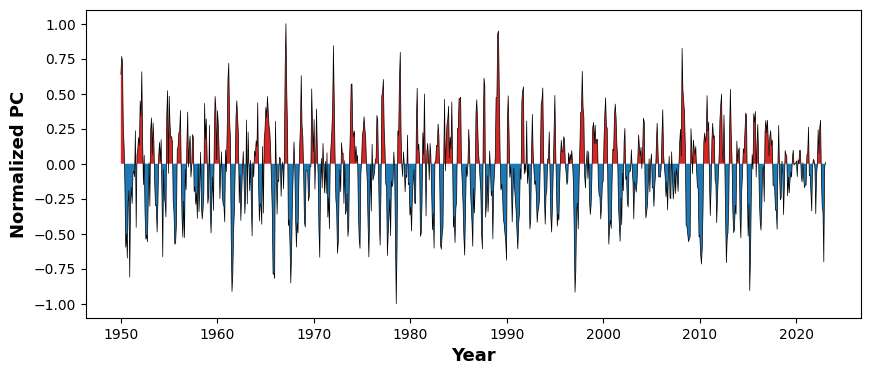

In [29]:
k = 3
sign = 1
l_0 = 180

plot_EoF(Global_eof,Global_varfrac,lon,lat,k,sign=sign,l_0=l_0)

x = np.linspace(start_year,end_year,len(Global.time))
plot_PC(x,Global_pc[:,k])

Mode 4, accounting for 3.3% of the total variance, is concentrated in the northern Pacific ocean. This region resembles the North Pacific Gyre Oscillation (NPGO), which is defined as the second mode of an EOF analysis done on the North Pacific basin.

Each mode can be explained by other regions SSTA, or EOF modes: 

i) For the first mode, it was concentrated in the El Nino region, an analysis of the SSTA only in this region would confirm that most of the SSTA global variance is explained by the ENSO.

ii) For the second mode, it was concentrated in the northern parts of the Atlantic and eastern Pacific ocean. The prinicpal component heavily resembles the AMO, which can be determined by an SSTA analysis on the Northern Atlantic ocean. At the North Eastern Pacific ocean, the North Pacific Gyre Oscillation can be compared by determining the second mode principal component for the Northern Pacific ocean.

iii) The third mode was concentrated at the Central and Northern Pacific ocean. This could be explained by both the ENM and the PDO. For the ENM, we would need to use the following index: 

$ENI = SSTA_{A} - 0.5 SSTA_{B} - 0.5 SSTA_{C}$,

where region A is $165^\circ$ E $-140^\circ$ W & $10^\circ$ S $-10^\circ$ N, 

region $B$ is $110^\circ$ W $-70^\circ$ W & $15^\circ$ S $-5^\circ$ N, 

and region $C$ is $125^\circ$ E $-145^\circ$ E & $10^\circ$ S $-20^\circ$ N.

The PDO is defined as the first mode of an EOF analysis on the North Pacific.

iv) Lastly, the fourth mode resembles the NPGO.


Let us set up some of these ocean cycles to compare the global SSTA variance.

In [30]:
Nino34 = Global.sel(latitude = (Global.latitude >= -5) & (Global.latitude <= 5),
                          longitude = (Global.longitude >= 140) & (Global.longitude <= 260)) # select Nino 3.4 region

NA = Global.sel(latitude = (Global.latitude >= 0) & (Global.latitude <= 90),
               longitude = (Global.longitude >= 280) & (Global.longitude <= 360)) # Select North Atlantic.

NP = Global.sel(latitude = (Global.latitude >= 20) & (Global.latitude <= 60),
                longitude = (Global.longitude >= 120) & (Global.longitude <= 240)) # Select North Pacific basin.

# For the El Nino Modoki Index.
NinoA = Global.sel(latitude = (Global.latitude >= -10) & (Global.latitude <= 10),
                   longitude = (Global.longitude >= 165) & (Global.longitude <= 320))

NinoB = Global.sel(latitude = (Global.latitude >= -15) & (Global.latitude <= 5),
                     longitude = (Global.longitude >= 250) & (Global.longitude <= 290))

NinoC = Global.sel(latitude = (Global.latitude >= -10) & (Global.latitude <= 20),
                        longitude = (Global.longitude >= 125) & (Global.longitude <= 145))


Retrieving the AMO, ENSO, and EMI ocean cycles.

In [31]:
AMO_ts = NA.mean(dim=['longitude','latitude']) # Atlantic Multidecadal Oscillation.
ENSO_ts = Nino34.mean(dim=['longitude','latitude']) # El Nino Southern Oscillation.
EMI_ts = NinoA.mean(dim=['longitude','latitude']) - 0.5*NinoB.mean(dim=['longitude','latitude']) - 0.5*NinoC.mean(dim=['longitude','latitude']) # El Nino Modoki Index.

Retrieving the North Pacific cycles through an EOF analysis on the North Pacific basin.

No overlap between eigenvalues.


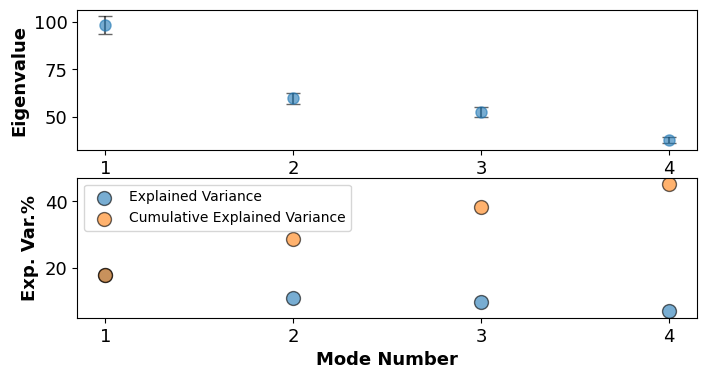

In [32]:
NP_eof,NP_pc,NP_varfrac,NP_lambdas = get_EOF(NP,4) # Perform EOF on North Pacific basin.


First, the PDO.

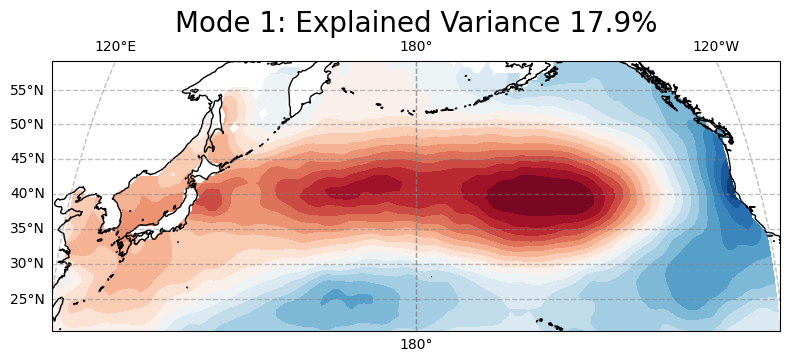

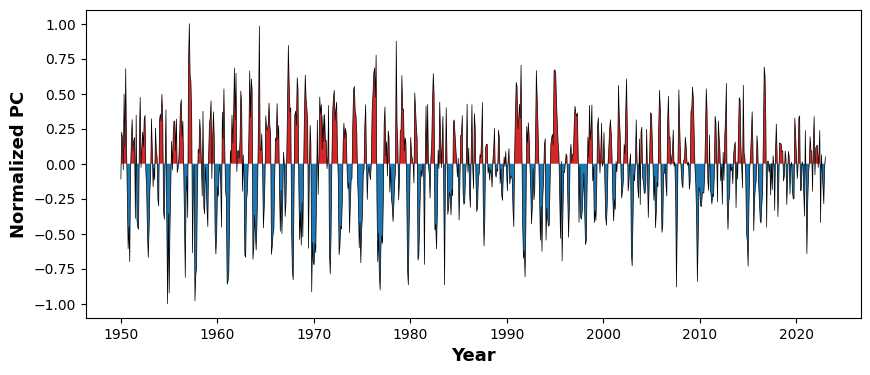

In [33]:
# Plotting the North Pacific EOF1 -- The Pacific Decadal Oscillation.
lat = NP.latitude.values
lon = NP.longitude.values
k = 0
sign = 1
l_0 = 180

plot_EoF(NP_eof,NP_varfrac,lon,lat,k,sign=sign,l_0=l_0)

x = np.linspace(start_year,end_year,len(NP.time))
plot_PC(x,NP_pc[:,k])

Secondly, the NPGO.

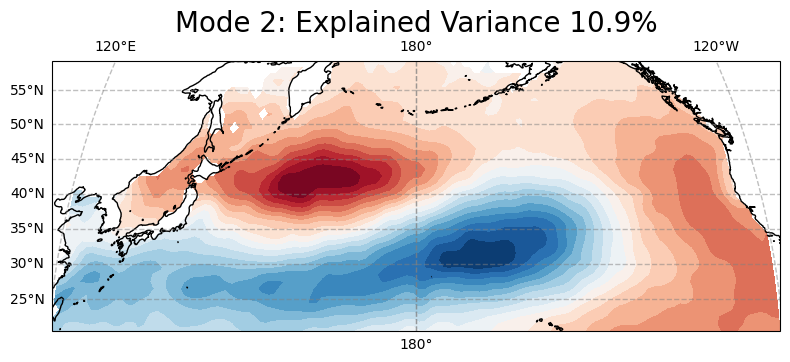

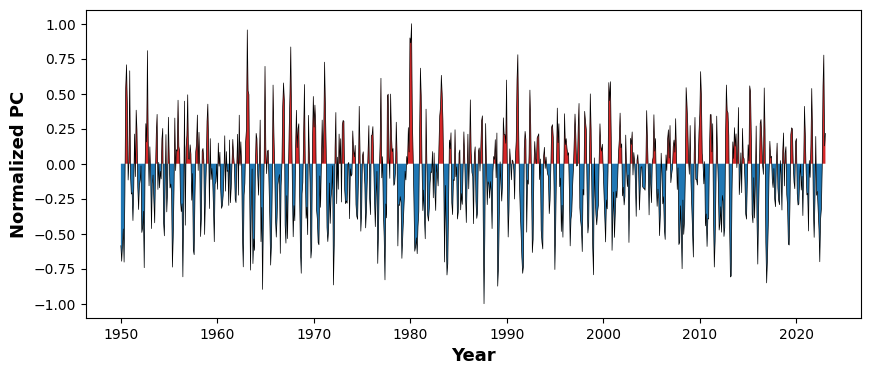

In [35]:
# Plotting the North Pacific EOF2 -- The North Pacific Gyre Oscillation.
lat = NP.latitude.values
lon = NP.longitude.values
k = 1
sign = 1
l_0 = 180

plot_EoF(NP_eof,NP_varfrac,lon,lat,k,sign=sign,l_0=l_0)

x = np.linspace(start_year,end_year,len(NP.time))
plot_PC(x,NP_pc[:,k])

Now, we compare each mode to an index using the Pearson correlation coefficient.

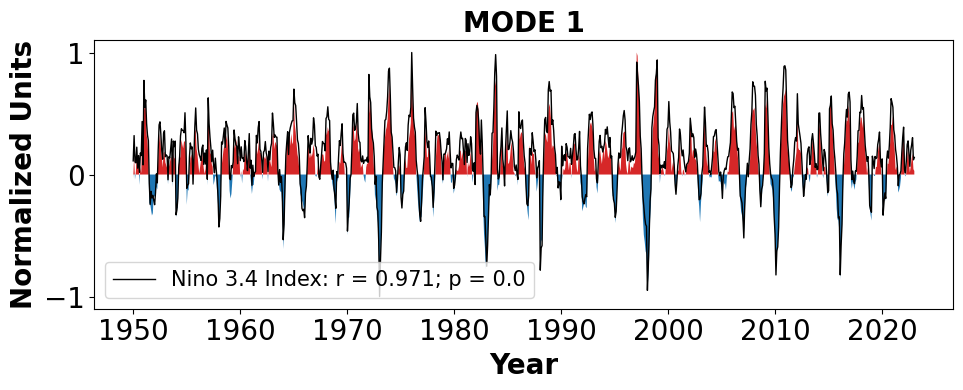

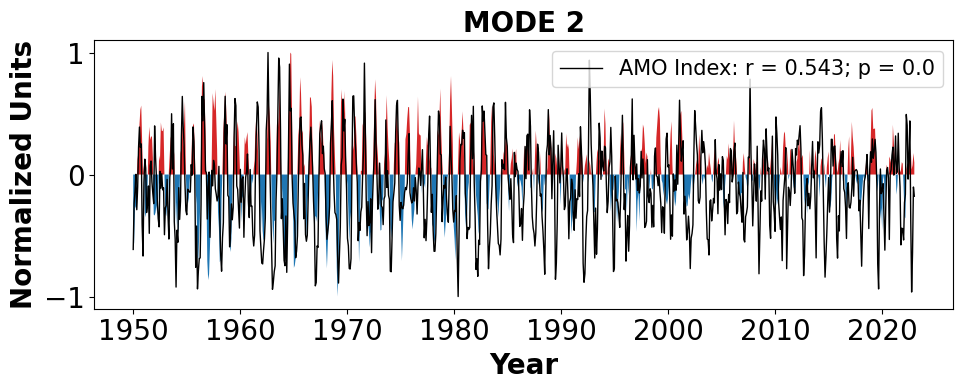

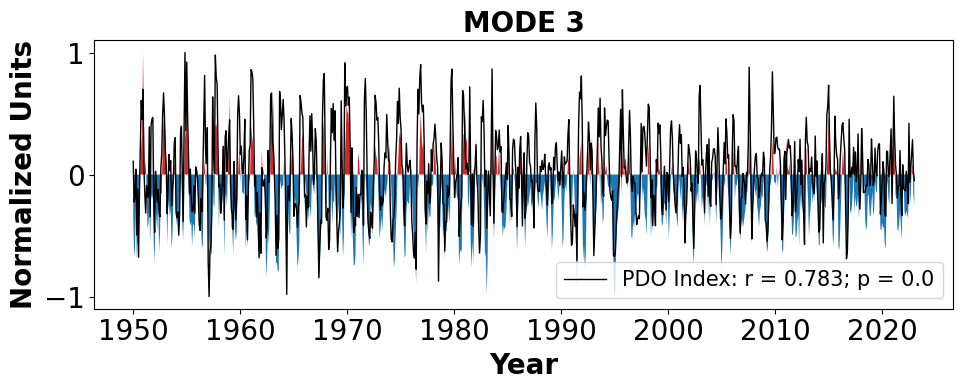

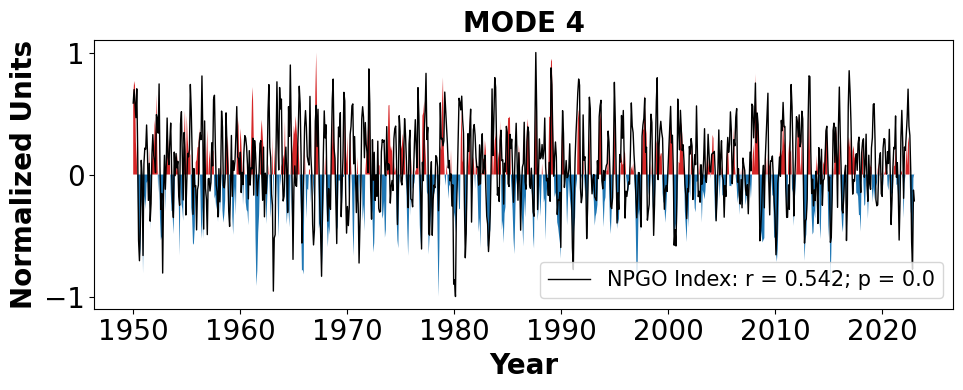

In [39]:

def plot_2ts(x,ts1,ts2,ts_label1,ts_label2, figb = True, color='k'):
    result = pearsonr(ts1,ts2)
    r = result.correlation
    p = result.pvalue
    if figb == True:
        fig = plt.figure(figsize=(10,4))
    plt.plot(x,ts2,linewidth=1,color=color,label=ts_label2+': r = '+str(round(r,3))+'; p = '+str(round(p,3)))
    plt.xlabel('Year',size=20,fontweight='bold')
    plt.ylabel('Normalized Units',size=20,fontweight='bold')
    plt.tick_params(labelsize=20)
    plt.fill_between(x, ts1, 0, where=ts1 >= 0, facecolor='tab:red', interpolate=True)
    plt.fill_between(x, ts1, 0, where=ts1 <= 0, facecolor='tab:blue', interpolate=True)
    plt.title(ts_label1, fontsize=20, fontweight='bold')
    plt.legend(fontsize=15)
    plt.tight_layout()

PC1 = ts_norm(Global_pc[:,0])
PC2 = ts_norm(Global_pc[:,1])
PC3 = ts_norm(Global_pc[:,2])
PC4 = ts_norm(Global_pc[:,3])

x = np.linspace(start_year,end_year,len(PC1))

plot_2ts(x,PC1,-1*ts_norm(ENSO_ts.sst),'MODE 1','Nino 3.4 Index')
plt.savefig('ENSO_Corr.svg',dpi=300)

plot_2ts(x,PC2,-1*ts_norm(AMO_ts.sst),'MODE 2','AMO Index')
plt.savefig('NAO_Corr.svg',dpi=300)

plot_2ts(x,PC3,-1*ts_norm(NP_pc[:,0]),'MODE 3','PDO Index')
plt.savefig('PDO_Corr.svg',dpi=300)

plot_2ts(x,PC4,-1*ts_norm(NP_pc[:,1]), 'MODE 4', 'NPGO Index')    
plt.savefig('NPGO_Corr.svg',dpi=300)


It is quite clear that the first mode, accounting for the most global SSTA variance, is the ENSO. The second mode is not as clear, but the AMO is strongly correlated. The third mode is mostly contributed by the PDO, and the fourth mode is not as clear but still has a quite strong correlation.

### IV. Fourier & Wavelet Transformation on the time-series.
Now, let us perform some Fourier and Wavelet analysis on these ocean cycles.

#### IV.1 ENSO

(6.0, -3.0)

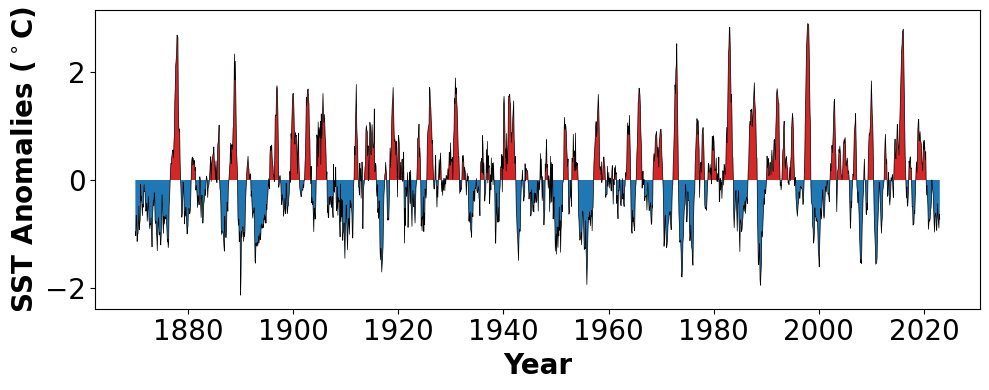

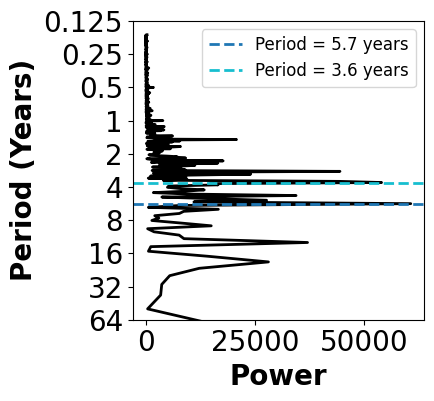

In [177]:
def plot_Power(y,t,upperlim=8):
    """
    Plot the power spectrum of a time series.

    Parameters
    ----------
            y : array
                Time series.

            t : array
                Time vector.

    Returns
    -------
            fig : matplotlib.figure.Figure
                  Figure object.

             ax : matplotlib.axes._subplots.AxesSubplot
                  Axes object.
    """
    # Set up Frequency.
    N = len(y) # Number of data points.
    dtime = t[1]-t[0] # Sampling interval.
    T = N*dtime # Total duration of the time series.
    df = 1/T # Sampling frequency.
    Nyquist_freq = 1/(2*dtime) # Nyquist frequency.
    f = np.arange(0,Nyquist_freq,df) # Frequencies.
    freq = np.linspace(0, 1/(2*dtime), N//2+1) # Frequency vector.
    freq[0] = 1e-10 # Avoid division by zero.

    # Perform Fourier transform.
    Y = fft(y) # Fourier transform.
    Y = np.abs(Y[0:N//2+1]) # Use only positive frequencies.

    # Get the power spectrum.
    PS = abs(Y)**2  # Power spectrum.
    peaks,_ = scipy.signal.find_peaks(PS, height=max(PS)*0.75, distance=1, threshold=10)

    # Plot the original time series.
    fig, ax = plt.subplots(figsize=(10,4))
    plt.plot(t,y,linewidth=0.5,color='k')
    plt.fill_between(t, y, 0, where=y >= 0, facecolor='tab:red', interpolate=True)
    plt.fill_between(t, y, 0, where=y <= 0, facecolor='tab:blue', interpolate=True)
    plt.xlabel('Year',size=20,fontweight='bold')
    plt.ylabel('SST Anomalies ($^\circ$C)',size=20,fontweight='bold')
    plt.tick_params(labelsize=20)
    #plt.xlim([1970,2000])
    plt.tight_layout()
    plt.savefig('TimeSeries.svg',dpi=300)

    # Plot the power spectrum.
    fig, ax = plt.subplots(figsize=(4,4))
    plt.plot(PS,np.log2(1/freq),linewidth=2, color='k')
    plt.ylabel('Period (Years)',size=20,fontweight='bold')
    plt.xlabel('Power',size=20,fontweight='bold')
    plt.tick_params(labelsize=20)

    cmap = plt.get_cmap('tab10')
    colors = [cmap(i) for i in np.linspace(0, 1, len(peaks))]
    for i in range(0,len(peaks)):
        plt.axhline(np.log2(1/freq[peaks[i]]),linestyle='--', color = colors[i],linewidth=2, label = 'Period = '+str(np.round(1/freq[peaks[i]],1))+' years')
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.savefig('PowerSpectrum.svg',dpi=300)

# Set up data.
Nino34 = anom.sel(latitude = (anom.latitude >= -5) & (anom.latitude <= 5),
                          longitude = (anom.longitude >= 190) & (anom.longitude <= 260)) # select Nino 3.4 region

ENSO = Nino34.mean(dim=['longitude','latitude']) # El Nino Southern Oscillation.

y_ENSO= ENSO.sst.values
y_ENSO -= y_ENSO.mean() # For a zero mean --> no peak at 0 frequency.
t = np.linspace(1870,2023,len(y)) # Time vector.

plot_Power(y_ENSO,t)
# log2 y-scaled.
plt.yticks(np.log2([0.125,0.25,0.5,1,2,4,8,16,32,64,128,256,512]),[0.125,0.25,0.5,1,2,4,8,16,32,64,128,256,512])
plt.ylim([np.log2(64),np.log2(0.125)])

Here, we can see a few different peaks. The dominating peak is at a perid of about $T\sim 5.55$ years. We get a range of about every $T\sim 3.6$ to $T \sim 5.6$ years the ENSO goes through a complete cycle. 

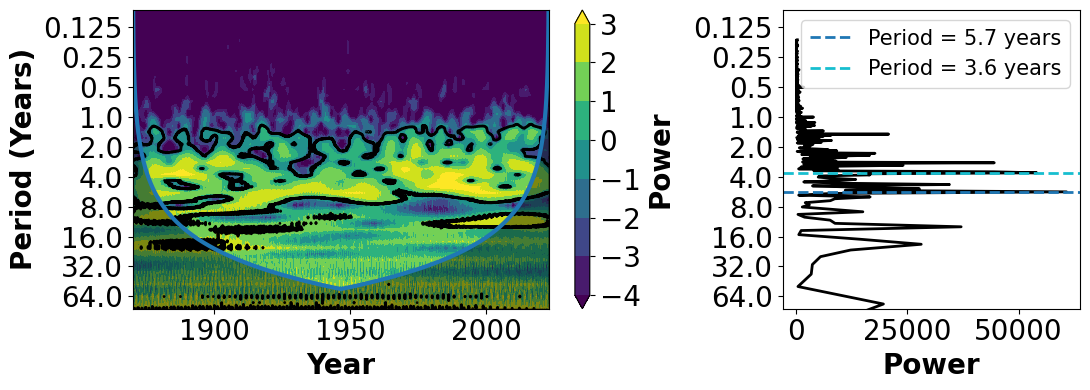

In [178]:
def get_coi(FF,df,N):
    """
    Calculate the cone of influence, see Torrence and Compo 1998 [1] section 2. g.
    Ref: [1] C. Torrence and G. P. Compo, A Practical Guide to Wavelet Analysis, Bull. Amer. Meteor. Soc. 79, 61 (1998).

    Parameters
    ----------
                FF : float
                     The Fourier period of the Morlet wavelet.
                df : float
                     The sampling frequency.
                 N : int
                     The length of the time series.

    Returns
    -------
               coi : numpy.ndarray
                     The cone of influence.
    """
    coi_coef = 2*df*FF*np.sqrt(2)
    ray1 =  coi_coef * np.arange(0, N / 2) # First half of the coi.
    ray2 = -coi_coef * np.arange(0, N / 2) + ray1[-1] # Second half of the coi, first half flipped
    coi = np.r_[ray1, ray2] # Concatenate the two halves.
    coi[0] = coi[-1] = 1e-6 # Set the first and last values to a small number to avoid division by zero.
    return coi

def get_Significance(power,frequencies,time_series,dof,alpha_lag,alpha_sig):
    """
    Calculate the significance of the wavelet power spectrum, see Torrence and Compo 1998 [1] sec. 4.
    Ref: [1] C. Torrence and G. P. Compo, A Practical Guide to Wavelet Analysis, Bull. Amer. Meteor. Soc. 79, 61 (1998).

    Parameters
    ----------
              power : numpy.ndarray
                      The wavelet power spectrum.

        frequencies : numpy.ndarray
                      The frequencies.

        time_series : numpy.ndarray
                      The time series.

                dof : float
                      The degrees of freedom.

          alpha_lag : float
                      The lag-1 autocorrelation of the time series.

          alpha_sig : float
                      The significance level.

    Returns
    -------
    significance : numpy.ndarray
                   The significance of the wavelet power spectrum, if greater than 1 then it is a significant result.
    """
    
    P_k = (1 - alpha_lag**2)/(1 + alpha_lag**2 - 2*alpha_lag*np.cos(2*np.pi*frequencies)) # Eq. 16 in Torrence and Compo 1998.
    
    # Find the value of chi (i.e., X) that corresponds to the specified significance level.
    X = np.linspace(0.01,5,50000) 
    chi2_cdf = gammainc(dof//2,dof*X/2) # Cumulative distribution function of the chi-squared distribution.
    idx = np.where(chi2_cdf >= 0.95)[0][0] # Significance level is equivalent to the same quantile level.
    chi2 = X[idx]*dof # The chi-squared value at the specificed significance level.

    upper_95CI = np.var(time_series)*P_k*chi2/dof # Eq. 18 in Torrence and Compo 1998.
    upper_95CI = np.tile(upper_95CI,(np.shape(power)[1],1)).T # Each significance level is the same for a given time step.

    significance = power/upper_95CI # Eq. 20 in Torrence and Compo 1998 ==> W_n(s)/W'_n(s) > 1 is significant, where W_n(s) and W'_n(s) is the measured and theoretical wavelet power spectrum, respectively. 
    
    return significance

def plot_Wavelet(y,t,scales,mother,fc,contourlevels):
    """
    Plot the wavelet power spectrum, see Torrence and Compo 1998 [1].
    Ref: [1] C. Torrence and G. P. Compo, A Practical Guide to Wavelet Analysis, Bull. Amer. Meteor. Soc. 79, 61 (1998).

    Parameters
    ----------
            y : array
                Time series.

            t : array
                Time vector.

        mother : string
                The mother wavelet.

            fc : float
                The Morlet wave's central frequency.

    Returns
    -------
            fig : matplotlib.figure.Figure
                  Figure object.

             ax : matplotlib.axes._subplots.AxesSubplot
                  Axes object.
    """
    # Perform the wavelet transformation using the Morlet wavelet.
    N = len(y) # Number of data points.
    dtime = t[1]-t[0] # Sampling interval.
    T = N*dtime # Total duration of the time series.
    df = 1/T # Sampling frequency.
    
    [coefficients, frequencies] = pywt.cwt(y,scales,mother,dtime) # cmorB-C, where B is the bandwidth and C = 2 is the central frequency.

    # Extract the period and power.
    period = 1/frequencies
    power = abs(coefficients)**2

    # Create a figure 
    fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [7, 4]})

    # Plot the wavelet power spectrum.
    im = ax[0].contourf(t,np.log2(period),np.log2(power),contourlevels,extend='both',cmap='viridis')
    for c in im.collections:
        c.set_rasterized(True)
    yticks = 2**np.arange(np.ceil(np.log2(period.min())),np.ceil(np.log2(period.max())))
    ax[0].set_yticks(np.log2(yticks),yticks)
    ax[0].set_xlabel('Year',size=20,fontweight='bold')
    ax[0].set_ylabel('Period (Years)',size=20,fontweight='bold')
    ax[0].tick_params(labelsize=20)
    cbar = plt.colorbar(im)
    cbar.ax.tick_params(labelsize=20)
    cbar.ax.set_ylabel('Power',fontsize=20,fontweight='bold')

    # Calculate the confidence interval.
    alpha_lag = 0.72 # Lag-1 autocorrelation of the time series, 0.72 for a red noise process, 0 for a white noise process.
    alpha_sig = 0.95 # Significance level.
    dof = 2 # Degrees of freedom for the Mortlet wavelet.
    significance = get_Significance(power,frequencies,y,dof,alpha_lag,alpha_sig)
    im = ax[0].contour(t,np.log2(period),significance,[-99,1],colors='k',linewidths=2) # Plot significance contour.
    for c in im.collections:
        c.set_rasterized(True)

    Fourier_factor = period[0]/scales[0] # The Fourier 'factor' of the Morlet wavelet --> converting scales to frequency (see Torrence and Compo 1998 sec. 2h).
    coi = get_coi(Fourier_factor,df,N) # Calculate the cone of influence.
    try:
        ax[0].plot(t,np.log2(coi / fc / df),linewidth=3) # Plot the cone of influence.
        ax[0].fill_between(t,np.log2(coi / fc / df),np.log2(period.max()),color='k',alpha=0.4) # Shade region outside the cone.
    except:
        ax[0].plot(t,np.log2(coi[:-1] / fc / df),linewidth=3) # Plot the cone of influence.
        ax[0].fill_between(t,np.log2(coi[:-1] / fc / df),np.log2(period.max()),color='k',alpha=0.4) # Shade region outside the cone.
        
    ax[0].set_ylim(np.log2([period.min(),period.max()]))
    ax[0].invert_yaxis()

    # Perform Fourier transform.
    freq = np.linspace(0, 1/(2*dtime), N//2+1) # Frequency vector.
    freq[0] = 1e-10 # Avoid division by zero.
    Y = fft(y) # Fourier transform.
    Y = np.abs(Y[0:N//2+1]) # Use only positive frequencies.

    # Get the power spectrum.
    PS = abs(Y)**2  # Power spectrum.
    peaks,_ = scipy.signal.find_peaks(PS, height=max(PS)*0.75, distance=1, threshold=10)

    # Plot the power spectrum.
    #fig, ax = plt.subplots(figsize=(4,4))
    ax[1].plot(PS,np.log2(1/freq),linewidth=2, color='k')
    #ax[1].set_ylabel('Period (Years)',size=20,fontweight='bold')
    ax[1].set_xlabel('Power',size=20,fontweight='bold')
    ax[1].tick_params(labelsize=20)
    ax[1].set_yticks(np.log2(yticks),yticks)
    ax[1].set_ylim(np.log2([period.min(),period.max()]))
    ax[1].invert_yaxis()

    cmap = plt.get_cmap('tab10')
    colors = [cmap(i) for i in np.linspace(0, 1, len(peaks))]
    for i in range(0,len(peaks)):
        ax[1].axhline(np.log2(1/freq[peaks[i]]),linestyle='--', color = colors[i],linewidth=2, label = 'Period = '+str(np.round(1/freq[peaks[i]],1))+' years')
    ax[1].legend(fontsize=15)
    plt.tight_layout()
    plt.savefig('PowerSpectrum.svg',dpi=300)

mother = 'cmor1-2' # Morlet wavelet.
scales = np.logspace(np.log10(2),np.log10(2048)) # Time Scales.
levels = [0.0625,0.125,0.25,0.5,1,2,4,8] # Contour levels.
contourlevels = np.log2(levels) # Contour levels in log2.
plot_Wavelet(y_ENSO,t,scales,mother,2,contourlevels) # Plot the wavelet power spectrum.

plt.savefig('Wavelet.svg',dpi=300)

The range of periods that is most influential and consistent tends to be around $T \sim 2$ to $T \sim 8$, which is the region inbetween the two red dotted horizontal lines. It also looks to be fluctuating quite a bit into the higher periods, espcially around the 1900's to the 1910's.

### IV.2 AMO

In [8]:
# Detrend.

global_anom = anom.mean(dim=['longitude','latitude'])
x = global_anom.time

# Linear trend finding
y = global_anom.sst
x = np.linspace(1870,2023,len(y))
slope, intercept, r_value, p_value, std_err = stats.linregress(x,y) # Linear regression

# Linear trend line
line = slope*x+intercept

linex = xr.DataArray(line, dims=('time'), coords={'time': anom.time})
g = anom - linex

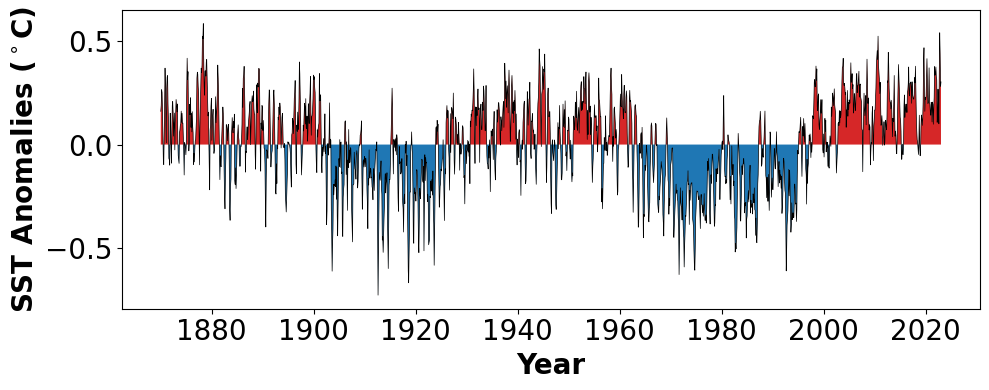

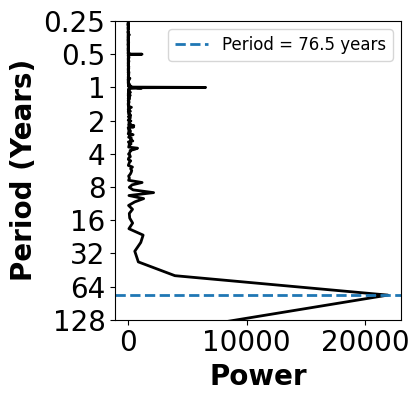

In [179]:
# Set up data.
NA = g.sel(latitude = (g.latitude >= 0) & (g.latitude <= 90),
                          longitude = (g.longitude >= 280) & (g.longitude <= 360)) # select Nino 3.4 region

AMO = NA.mean(dim=['longitude','latitude'])

y_AMO = AMO.sst.values
y_AMO -= y_AMO.mean() # For a zero mean --> no peak at 0 frequency.
t = np.linspace(1870,2023,len(y_AMO)) # Time vector.

plot_Power(y_AMO,t)
plt.ylim([0,np.log2(200)])
plt.yticks(np.log2([0.125,0.25,0.5,1,2,4,8,16,32,64,128,256,512]),[0.125,0.25,0.5,1,2,4,8,16,32,64,128,256,512])
plt.ylim([np.log2(128),np.log2(0.25)])
plt.savefig('PowerSpectrum.svg',dpi=300)


Despite the noisiness, there's a clear dominant period of $\sim 76.5$ years. Regardless, we can apply a moving average to clean it up.

In [180]:
# Create moving average
def moving_average(x, w):
    """
    Calculate the moving average of a time series.

    Parameters
    ----------
        x : array
            Time series.

        w : int
            Window size.

    Returns
    -------
        y : array
            The moving average of the time series.
    """
    return np.convolve(x, np.ones(w), 'valid') / w

AMO_MA = moving_average(AMO.sst,12*10) # 10 year moving average.

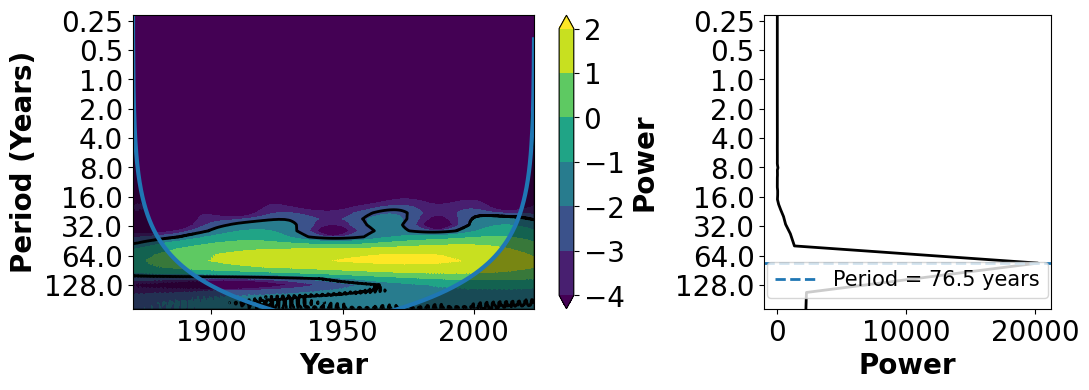

In [194]:
y_AMO = AMO_MA
t = np.linspace(1870,2023,len(y_AMO)) # Time vector.

mother = 'cmor1-0.8'
scales = np.logspace(np.log10(2),np.log10(2048))

contourlevels = [0.0625,0.125,0.25,0.5,1,2,4]
contourlevels = np.log2(contourlevels)
plot_Wavelet(y_AMO,t,scales,mother,0.8,contourlevels)
plt.savefig('Wavelet.svg',dpi=300)

And as expected, we get periods whose concentration are in the ranges of $\sim 40$ years to $\sim 80$ years.

### IV.3 PDO & NPGO

No overlap between eigenvalues.


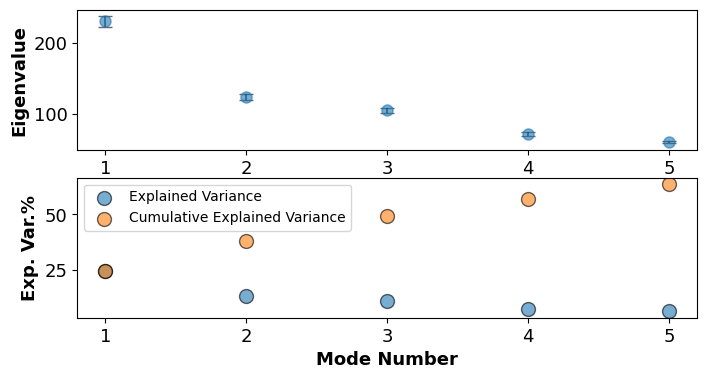

In [13]:
NP = g.sel(latitude = (g.latitude >= 20) & (g.latitude <= 60),
                longitude = (g.longitude >= 120) & (g.longitude <= 240)) # Select North Pacific basin.

# We perform an EOF on the North Pacific basin to retrieve the PDO.
NP_eof,NP_pc,NP_varfrac,NP_lambdas = get_EOF(NP,5)


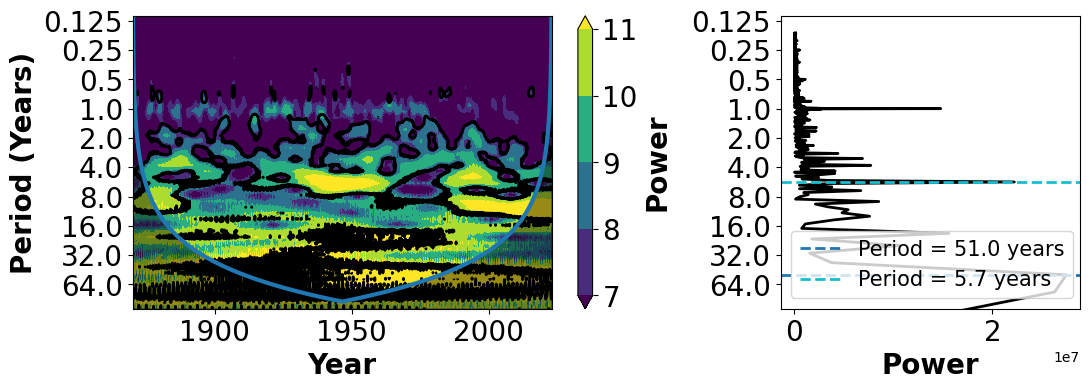

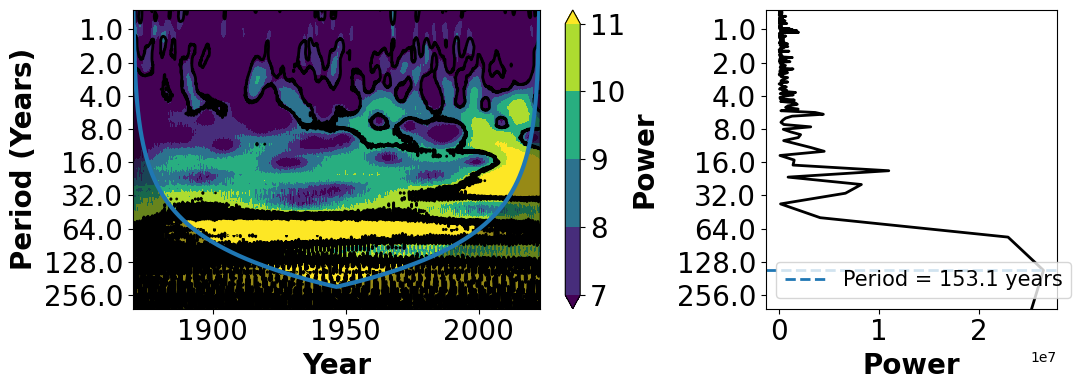

In [186]:
y_NDO = NP_pc[:,0]
y_NDO -= y_NDO.mean() # For a zero mean.

y_NPGO = NP_pc[:,1]
y_NPGO -= y_NPGO.mean() # For a zero mean.

t = np.linspace(1870,2023,len(y_NDO)) # Time vector.

mother = 'cmor1-1.5'
scales = np.logspace(np.log10(2),np.log10(2048))
levels=[128,256,512,1024,2048]
contourlevels = np.log2(levels)
plot_Wavelet(y_NDO,t,scales,mother,1.5,contourlevels)
plt.savefig('Wavelet PDO.svg',dpi=300)

mother = 'cmor1-1'
scales = np.logspace(np.log10(8),np.log10(2**12))
levels=[128,256,512,1024,2048]
contourlevels = np.log2(levels)
plot_Wavelet(y_NPGO,t,scales,mother,1,contourlevels)
plt.savefig('Wavelet NPGO.svg',dpi=300)


Both of these time series are quite noisy. Let us apply a moving average. 

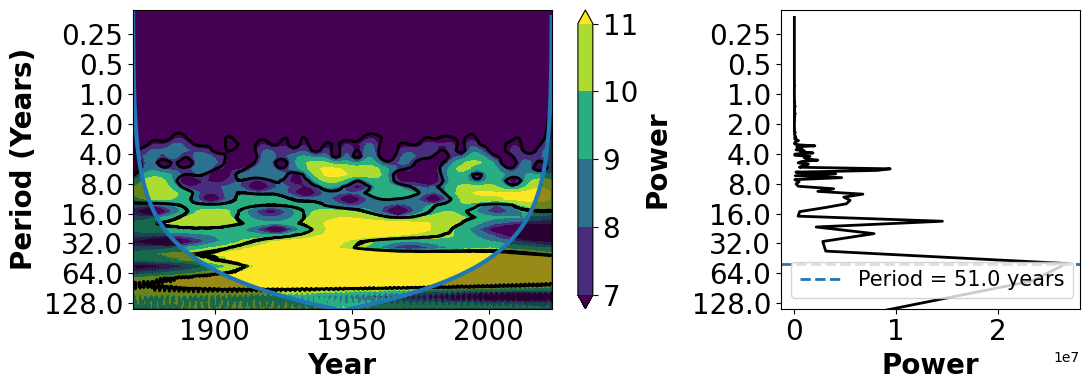

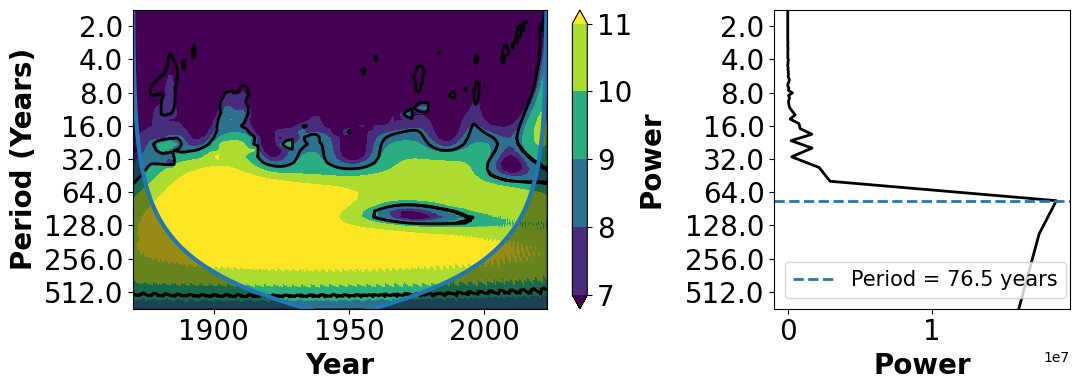

In [193]:
y_PDO = moving_average(NP_pc[:,0],12*2) # 2 year moving average.
y_NPGO = moving_average(NP_pc[:,1],12*10) # 10 year moving average.

t = np.linspace(1870,2023,len(y_PDO)) # Time vector.

mother = 'cmor1-1.2'
scales = np.logspace(np.log10(2),np.log10(2048))
levels=[128,256,512,1024,2048]
contourlevels = np.log2(levels)
plot_Wavelet(y_PDO,t,scales,mother,1.2,contourlevels)
plt.savefig('Wavelet PDO.svg',dpi=300)

t = np.linspace(1870,2023,len(y_NPGO)) # Time vector.
mother = 'cmor1-0.5'
scales = np.logspace(np.log10(8),np.log10(2**12))
levels=[128,256,512,1024,2048]
contourlevels = np.log2(levels)
plot_Wavelet(y_NPGO,t,scales,mother,0.5,contourlevels)
plt.savefig('Wavelet NPGO.svg',dpi=300)



Looks like there's a bit of variance in the PDO with most of its power being concentrated in the $\sim 30$ year to $\sim 100$ year period. The NPGO has large variance with its power concentrated in the $\sim 32$ year to $\sim 256$ year period.